# The dataset, from the original scan to tiles and crops

Every other notebook reads files this one makes. Run it first.

The data is the **ISPRS Wytham benchmark** (Cherlet et al. 2026, CC BY 4.0, https://doi.org/10.5281/zenodo.16875688): a terrestrial laser scan of Wytham Woods, UK, with every tree segmented by hand. We keep a copy of it, and of everything built from it, in one Hugging Face dataset: [haag-lidar/wytham-isprs-tiles](https://huggingface.co/datasets/haag-lidar/wytham-isprs-tiles). It is public, so no login is needed.

This notebook has two modes, set by `MODE` in the first cell:

- **`download`** (the default): fetch the finished tiles and crops, 0.9 GB. Use this to get to the other notebooks quickly, for example on Colab. It gives exactly the files the published model was trained and scored on.
- **`build`**: fetch the original scan, 3.3 GB, and cut the tiles and crops from it here. Use this to see or change how the data is made. On a laptop it took 90 seconds and 7 GB of memory, with no GPU.

Both modes skip any file that is already on disk. After Step 2 the notebook is the same in both modes: it only reads what is on disk.

What gets made, in `data/wytham_isprs/`:

| Folder | What | Used by |
|---|---|---|
| `raw/` | The authors' three files, unchanged (build mode only) | this notebook |
| `tiles/` | 30 m tiles, ground still in | `01_auto_prompt`, `03_benchmark`, `04_inference_steps` |
| `crops/` | 12 m crops, ground removed | `02_train`, `03_benchmark` |
| `summary.json` | The settings and counts of the build | this notebook |

In [1]:
import json
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from treeseg.data.download import compare_with_published, fetch
from treeseg.data.overview import load_overview, plot_crop_windows, plot_crops, plot_ground_removed, plot_strips, split_checks, tile_table
from treeseg.data.prepare import build_dataset

MODE = os.environ.get("TREESEG_DATA_MODE", "download")  # "download" or "build"

cfg = yaml.safe_load(open(os.environ.get("TREESEG_CONFIG", "configs/data/isprs_wytham.yaml")))
#a build can be sent to another folder, to compare it with the copy already on disk
cfg["out_dir"] = os.environ.get("TREESEG_DATA_OUT", cfg["out_dir"])
OUT = cfg["out_dir"]
TILE_DIR, CROP_DIR = os.path.join(OUT, "tiles"), os.path.join(OUT, "crops")
print(f"mode: {MODE}. Original scan in {cfg['source_dir']}, tiles and crops in {OUT}")

mode: download. Original scan in data/wytham_isprs/raw, tiles and crops in data/wytham_isprs


## Step 1: get the files

`fetch` downloads one part of the Hugging Face dataset and keeps its folder names. A file that is already on disk and unchanged is not downloaded again.

In [2]:
if MODE == "build":
    fetch("raw", os.path.dirname(cfg["source_dir"]))
    for split, filename in cfg["strips"].items():
        print(f"{split}: {filename}, {os.path.getsize(os.path.join(cfg['source_dir'], filename)) / 1e9:.2f} GB")
else:
    fetch("built", OUT)
    print(f"{len(os.listdir(TILE_DIR))} tile files, " + ", ".join(f"{len(os.listdir(os.path.join(CROP_DIR, s)))} {s} crops" for s in cfg["strips"]))

45 tile files, 182 train crops, 56 val crops, 56 test crops


## Step 2: build the tiles and crops (build mode only)

`build_dataset` takes each of the authors' three strips through four stages. The settings are in `configs/data/isprs_wytham.yaml`.

1. **Thin** the scan to one point per 5 cm cube. A cube takes the label most of its points have.
2. **Cut 30 m tiles** from the thinned strip. Every point is kept, ground included, because the benchmark removes ground itself when it loads a tile.
3. **Remove ground** with a cloth simulation filter, one tile at a time, exactly as the benchmark does.
4. **Cut 12 m crops** from what is left, every 6 m, so neighbouring crops overlap by half. A crop with more than 100,000 points keeps a random 100,000.

The authors' strips are our split: nothing here decides which tree goes to train, val or test.

In download mode this cell only reads `summary.json`, which is the record of the build that made the published files.

In [3]:
if MODE == "build":
    summary = build_dataset(cfg)
else:
    summary = json.load(open(os.path.join(OUT, "summary.json")))

pd.DataFrame([{"strip": split, "points in the original": f"{row['raw_points']:,}", "after thinning to 5 cm": f"{row['voxels']:,}",
               "removed as ground": f"{row['removed_as_ground']:.1%}", "tree points lost to ground removal": f"{row['tree_points_lost']:.2%}",
               "crops": len(row["crops"])} for split, row in summary["strips"].items()])

,strip,points in the original,after thinning to 5 cm,removed as ground,tree points lost to ground removal,crops
0,train,"102,602,005","35,755,364",16.3%,0.24%,182
1,val,"30,497,066","10,435,774",16.2%,0.29%,56
2,test,"30,016,364","10,585,228",14.1%,0.36%,56


## Step 3: the strips and the tiles

The whole scan from above. Each tile is outlined in its strip's colour: **blue train, yellow val, red test**. Points on a tree are coloured by tree, and everything else is grey.

Things to look for:

- The three strips sit side by side, with val in the middle.
- A tree on a strip boundary is cut in two, with one part in each strip. That is why val shares trees with its neighbours.

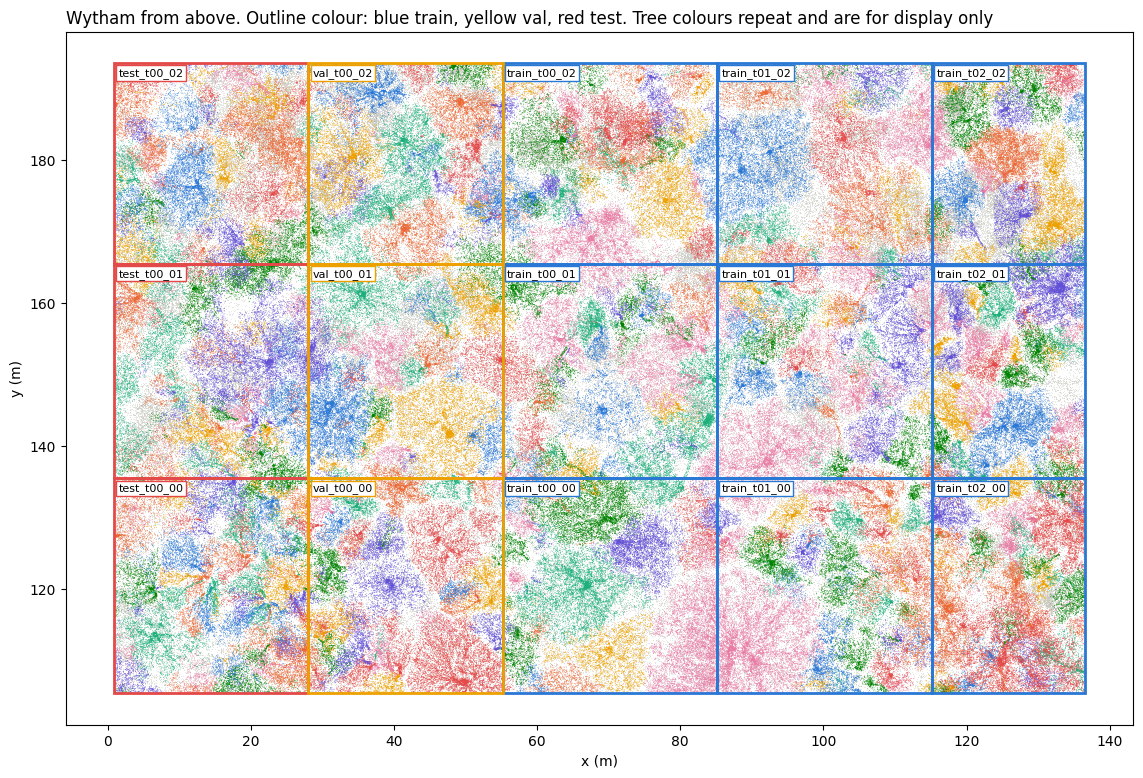

In [4]:
tiles = load_overview(TILE_DIR)
plot_strips(tiles)
plt.show()

In [5]:
tile_rows = pd.DataFrame(tile_table(TILE_DIR))
display(tile_rows.groupby("strip", sort=False).agg(tiles=("tile", "count"), points=("points", "sum")).assign(points=lambda t: t["points"].map("{:,}".format)))
tile_rows.assign(points=tile_rows["points"].map("{:,}".format))

,tiles,points
strip,,
test,3,"10,585,228"
train,9,"35,755,364"
val,3,"10,435,774"


,tile,strip,points,trees
0,isprs_test_t00_00,test,"3,200,418",118
1,isprs_test_t00_01,test,"3,668,590",85
2,isprs_test_t00_02,test,"3,716,220",74
3,isprs_train_t00_00,train,"4,176,277",44
4,isprs_train_t00_01,train,"3,995,185",55
5,isprs_train_t00_02,train,"3,908,771",66
6,isprs_train_t01_00,train,"4,957,968",72
7,isprs_train_t01_01,train,"4,451,575",84
8,isprs_train_t01_02,train,"4,540,339",49
9,isprs_train_t02_00,train,"3,541,650",74


## Step 4: the crops

The model never sees a whole tile. It trains on 12 m crops, and at inference each click is run inside a 12 m window. The blue squares below are the crop windows of one strip. They are 6 m apart, so every spot away from the edge is inside 4 crops.

Change `STRIP` and `CROP` to look at others.

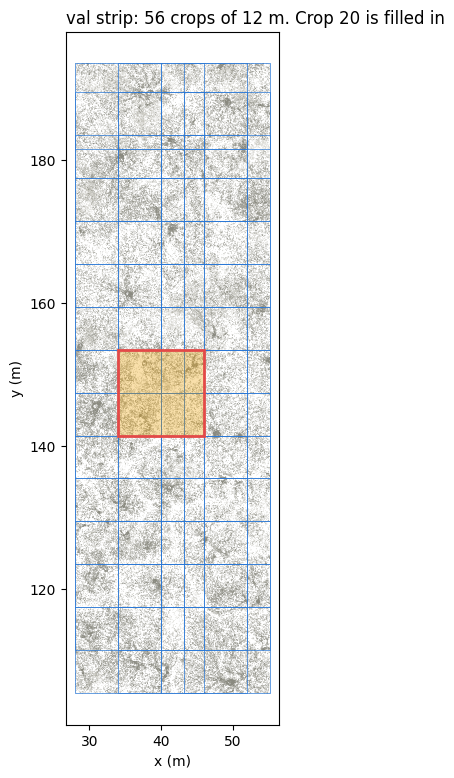

In [6]:
STRIP = "val"
CROP = 20

crops = summary["strips"][STRIP]["crops"]
plot_crop_windows(tiles, STRIP, crops, cfg["crop_m"], highlight=CROP)
plt.show()

### One window, before and after

The same 12 m window from the side. Left: as it is in the tiles, with the ground. Right: the crop, after ground removal. Dark grey points are not on any tree: ground on the left, and low plants that the filter kept on the right.

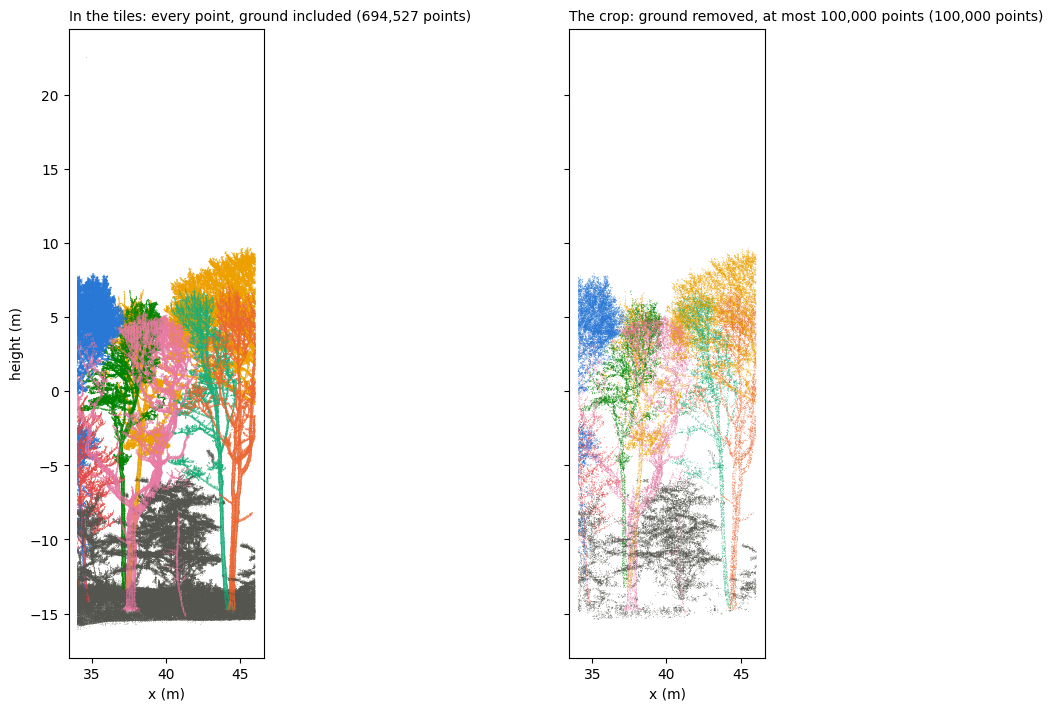

In [7]:
crop_path = os.path.join(CROP_DIR, STRIP, crops[CROP]["crop"] + ".npz")
plot_ground_removed(TILE_DIR, crop_path, crops[CROP]["origin_xy"], cfg["crop_m"])
plt.show()

### A few training crops

Top row from above, bottom row from the side. Each colour is one tree. A crop usually holds several trees, and most of them are cut by the crop's edge.

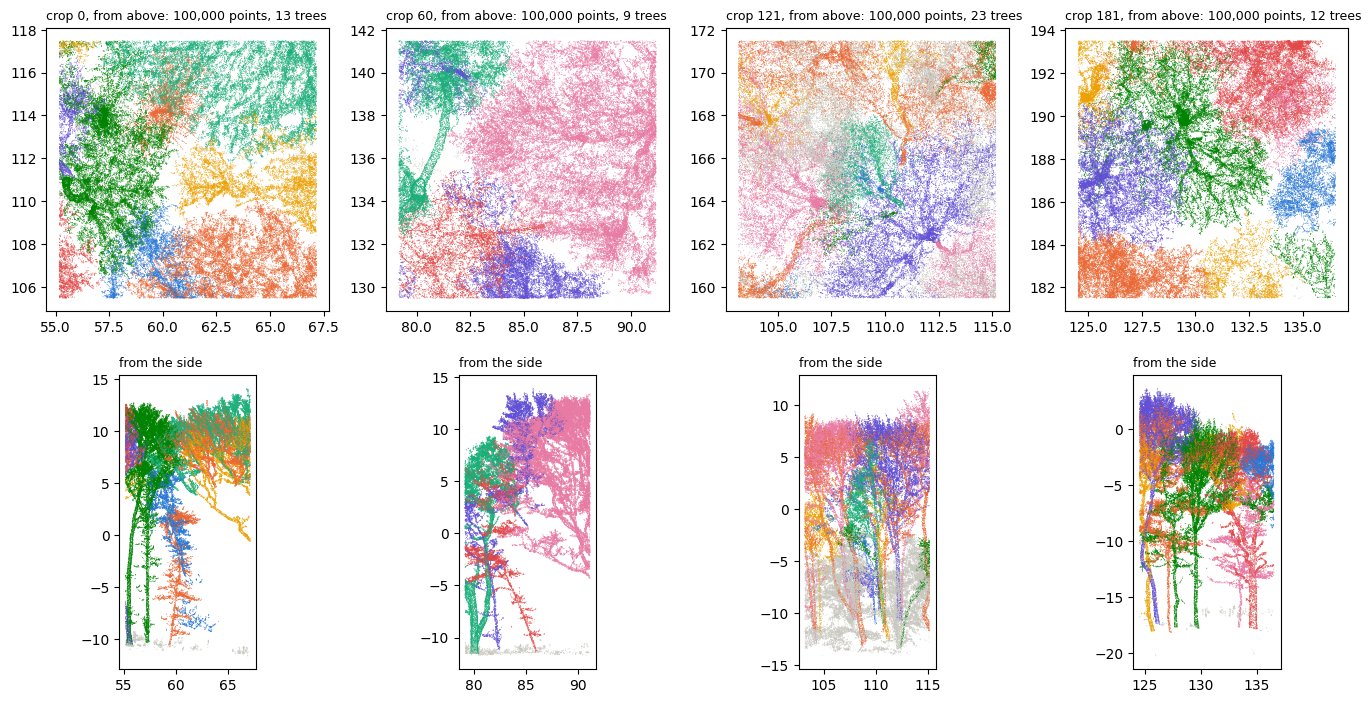

,strip,crops,median points per crop,median trees per crop
0,train,182,100000,17
1,val,56,100000,15
2,test,56,100000,24


In [8]:
n_train = len(summary["strips"]["train"]["crops"])
plot_crops(os.path.join(CROP_DIR, "train"), [0, n_train // 3, 2 * n_train // 3, n_train - 1])
plt.show()

pd.DataFrame([{"strip": split, "crops": len(row["crops"]), "median points per crop": int(pd.Series([c["n_points"] for c in row["crops"]]).median()),
               "median trees per crop": int(pd.Series([c["n_trees"] for c in row["crops"]]).median())} for split, row in summary["strips"].items()])

## Step 5: check the split

Every result in this project rests on these claims, so they are counted here from the labels and not taken on trust.

- **Train and test must share no trees.** Otherwise a test score would partly measure memory.
- **Val shares cut trees with both neighbours.** So val is for choosing a checkpoint and for diagnosis, never for a reported result.
- **The test strip is for final scores only.** It has been scored once. Do not tune on it.

The authors' test strip has 245 trees and the table below counts 244. One tree of 176 points is so small that no 5 cm cube has it as its most common label, so it disappears in thinning. Scoring ignores trees under 200 points, so no score changes.

In [9]:
checks = pd.DataFrame(split_checks(TILE_DIR, tiles))
shared = int(checks.loc[checks["check"].str.contains("must be 0", regex=False), "value"].iloc[0])
assert shared == 0, f"{shared} trees are in both train and test"
on_disk = {split: len(os.listdir(os.path.join(CROP_DIR, split))) for split in cfg["strips"]}
assert all(on_disk[split] == len(row["crops"]) for split, row in summary["strips"].items()), f"crops on disk {on_disk} do not match summary.json"
checks

,check,value
0,trees in train,431
1,trees in val,178
2,trees in test,244
3,trees in both train and test (must be 0),0
4,trees in both val and train,31
5,trees in both val and test,40
6,"gap between train and test strips, metres",27.1


### Is this build the same as the published copy? (build mode only)

A rebuild should give the files on Hugging Face. This compares the two without downloading them: tile labels by checksum, and each crop by its window, point count and tree count.

Thinning and tile cutting are exact, so they should match everywhere. Ground removal is not guaranteed to give identical results on different machines, so the crop rows are where a difference would show. A rebuild on the Mac that made the published files matched on every row; other machines have not been compared yet.

In [10]:
if MODE == "build":
    display(pd.DataFrame(compare_with_published(OUT)))
else:
    print("download mode: these are the published files, so there is nothing to compare")

download mode: these are the published files, so there is nothing to compare


## Next

`01_auto_prompt.ipynb` takes one tile, removes the ground and places clicks on the trees.